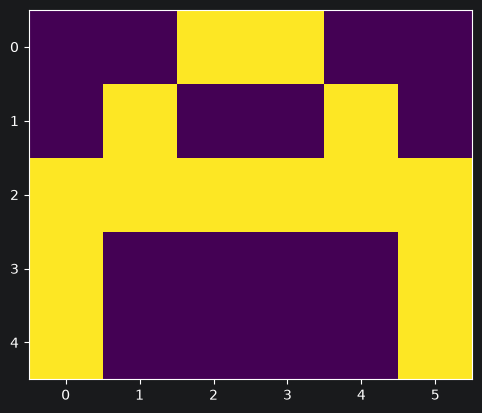

In [3]:
import numpy as np
import matplotlib.pyplot as plt
# Creating data set

# A
a =[0, 0, 1, 1, 0, 0,
   0, 1, 0, 0, 1, 0,
   1, 1, 1, 1, 1, 1,
   1, 0, 0, 0, 0, 1,
   1, 0, 0, 0, 0, 1]
# B
b =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0]
# C
c =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 1, 1, 1, 0]

# Creating labels
y =[[1, 0, 0],
   [0, 1, 0],
   [0, 0, 1]]

# visualizing the data, plotting A.
plt.imshow(np.array(a).reshape(5, 6))
plt.show()

In [4]:
# converting data and labels into numpy array
x =[np.array(a).reshape(1, 30), np.array(b).reshape(1, 30),
                                np.array(c).reshape(1, 30)]
y = np.array(y)
# Printing data and labels
print(x, "\n\n", y)

[array([[0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
        0, 1, 1, 0, 0, 0, 0, 1]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 1, 1, 1, 1, 0]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 1, 1, 1, 1, 0]])] 

 [[1 0 0]
 [0 1 0]
 [0 0 1]]


In [9]:
# activation function
def sigmoid(x):
	return 1/(1 + np.exp(-x))

# Creating the Feed forward neural network
def f_forward(x, w1, w2):
	z1 = x.dot(w1)    # input from layer 1
	a1 = sigmoid(z1)  # out put of layer 2
	z2 = a1.dot(w2)   # input of out layer
	a2 = sigmoid(z2)  # output of out layer
	return a2

# initializing the weights randomly
def generate_wt(x, y):
	li =[]
	for i in range(x * y):
		li.append(np.random.randn())
	return np.array(li).reshape(x, y)

# for loss we will be using mean square error(MSE)
def loss(out, Y):
	s =(np.square(out-Y))
	s = np.sum(s)/len(y)
	return s

# Back propagation of error
def back_prop(x, y, w1, w2, alpha):

	# hidden layer
	z1 = x.dot(w1)
	a1 = sigmoid(z1)
	z2 = a1.dot(w2)
	a2 = sigmoid(z2)

	# error in output layer
	d2 =(a2-y)
	d1 = np.multiply(w2.dot(d2.transpose()).transpose(),
								np.multiply(a1, 1-a1))
	# Gradient for w1 and w2
	w1_adj = x.transpose().dot(d1)
	w2_adj = a1.transpose().dot(d2)

	# Updating parameters
	w1 = w1-(alpha * w1_adj)
	w2 = w2-(alpha * w2_adj)

	return w1, w2

In [6]:
w1 = generate_wt(30, 5)
w2 = generate_wt(5, 3)

print(w1, "\n\n", w2)

[[-7.60562089e-01  2.04068384e+00 -1.16578541e-01 -2.14144843e+00
  -7.14354701e-02]
 [ 1.45211004e+00 -6.07008655e-01 -7.84826516e-01 -1.12218448e+00
   8.87141564e-01]
 [-4.79804304e-01  1.74461079e-01 -1.24896436e+00 -7.99019203e-01
  -7.72240995e-01]
 [ 1.26951802e+00  5.47588612e-02  7.39857589e-02  7.32930033e-01
  -4.18501392e-01]
 [-1.01706431e+00  1.96840764e-01  2.76929950e-01 -9.04257099e-01
  -2.31036366e-01]
 [-1.54168638e-01  1.60154952e+00  7.76451958e-01  7.30694544e-01
   2.46583706e+00]
 [ 1.17774802e+00 -2.89648376e-01 -1.41457164e-01  2.93376107e+00
   8.41397065e-01]
 [-1.04699970e+00 -1.56364232e+00  1.45101539e-01  1.14344726e+00
  -2.04624287e-01]
 [-1.04677973e-01 -1.16041559e+00 -3.62130121e-04 -9.53985685e-01
  -1.03866404e+00]
 [-1.12762458e+00 -1.12100187e+00 -2.62683536e-01  2.33071362e-03
  -8.66907389e-01]
 [-1.03189399e+00  8.22491368e-01 -3.69250307e-02 -6.65510552e-01
  -5.60539500e-01]
 [ 8.23444082e-01  1.89395038e-01 -3.07902161e-01  8.48116477e-01

epochs: 1 ======== acc: 99.9999999954323
epochs: 1 ======== acc: 99.99999999099722
epochs: 1 ======== acc: 99.99999998843275
epochs: 10001 ======== acc: 99.99999999558075
epochs: 10001 ======== acc: 99.99999999128978
epochs: 10001 ======== acc: 99.99999998880884
epochs: 20001 ======== acc: 99.99999999572209
epochs: 20001 ======== acc: 99.99999999156832
epochs: 20001 ======== acc: 99.9999999891669
epochs: 30001 ======== acc: 99.99999999585675
epochs: 30001 ======== acc: 99.99999999183369
epochs: 30001 ======== acc: 99.99999998950804
epochs: 40001 ======== acc: 99.99999999598515
epochs: 40001 ======== acc: 99.99999999208673
epochs: 40001 ======== acc: 99.99999998983331
epochs: 50001 ======== acc: 99.99999999610766
epochs: 50001 ======== acc: 99.99999999232818
epochs: 50001 ======== acc: 99.99999999014369
epochs: 60001 ======== acc: 99.99999999622466
epochs: 60001 ======== acc: 99.99999999255876
epochs: 60001 ======== acc: 99.99999999044007
epochs: 70001 ======== acc: 99.99999999633646
ep

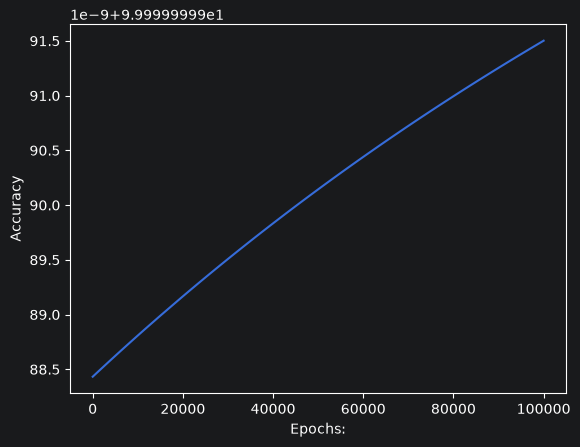

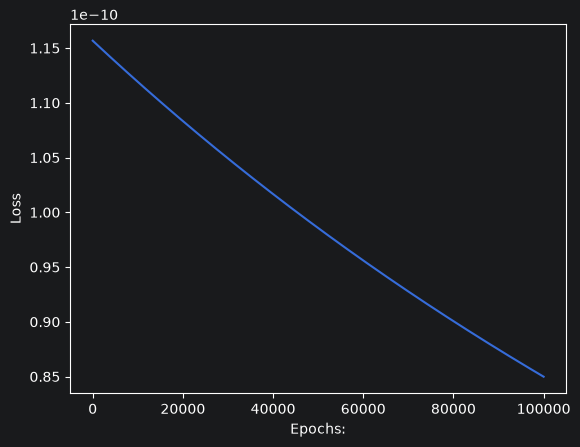

In [15]:
def train(x, Y, w1, w2, alpha = 0.01, epoch = 10):
	acc =[]
	losss =[]
	for j in range(epoch):
		l =[]
		for i in range(len(x)):
			out = f_forward(x[i], w1, w2)
			l.append(loss(out, Y[i]))
			w1, w2 = back_prop(x[i], y[i], w1, w2, alpha)
			if j % 10000 == 0:
				print("epochs:", j + 1, "======== acc:", (1-(sum(l)/len(x)))*100)
		acc.append((1-(sum(l)/len(x)))*100)
		losss.append(sum(l)/len(x))
	return(acc, losss, w1, w2)

acc, losss, w1, w2 = train(x, y, w1, w2, 0.1, 100000)


# plotting accuracy
plt.plot(acc)
plt.ylabel('Accuracy')
plt.xlabel("Epochs:")
plt.show()

# plotting Loss
plt.plot(losss)
plt.ylabel('Loss')
plt.xlabel("Epochs:")
plt.show()

Image is of letter A.


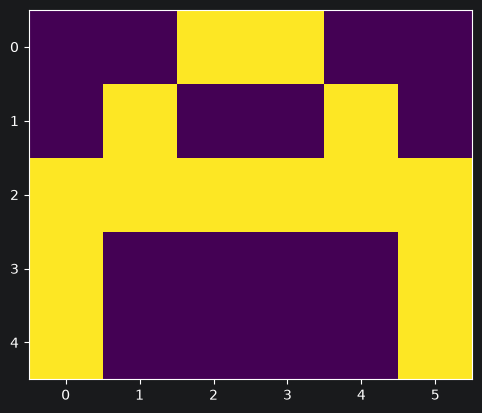

Image is of letter B.


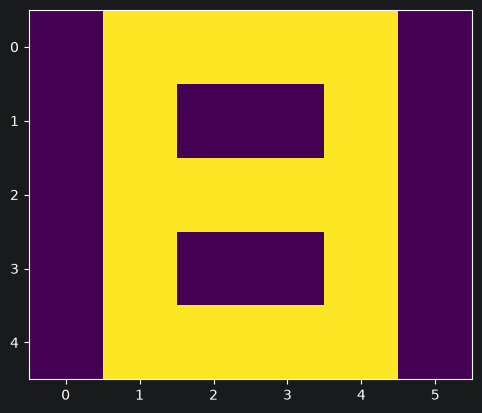

Image is of letter C.


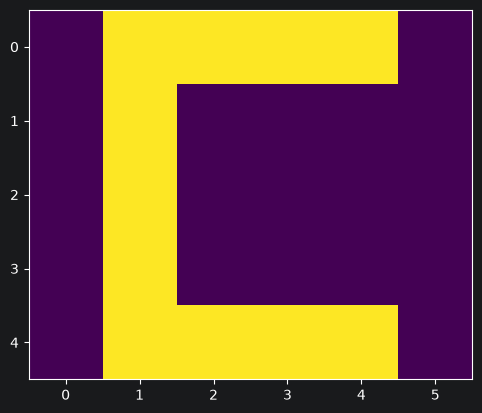

In [7]:
def predict(x, w1, w2):
	Out = f_forward(x, w1, w2)
	maxm = 0
	k = 0
	for i in range(len(Out[0])):
		if(maxm<Out[0][i]):
			maxm = Out[0][i]
			k = i
	if k == 0:
		print("Image is of letter A.")
	elif k == 1:
		print("Image is of letter B.")
	else:
		print("Image is of letter C.")
	plt.imshow(x.reshape(5, 6))
	plt.show()
# Example: Predicting for letter 'B'
for i in range(3):
	predict(x[i], w1, w2)